## Load data

load data from ChallengeDT/datasource just the data set call "youtube-users-by-coountry".

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as ptl
import seaborn as sns

df = pd.read_csv("/home/mikes/ChallengeDT/datasource/youtube-users-by-country-2025.csv")

#Data Frame shape
print(df.shape)

#Data Frame general information
print(f"Data Frame info: {df.info()}")

#Firts Fivr rows from the data frame
print(f"first five rows from the data set: \n\n {df.head()}")

#Duplicates rows
print(f"Duplicates rows: {df.duplicated().sum()}")

(87, 6)
<class 'pandas.DataFrame'>
RangeIndex: 87 entries, 0 to 86
Data columns (total 6 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   flagCode                              87 non-null     str    
 1   country                               87 non-null     str    
 2   YouTubeUsers_TotalUsers_Num_2024Feb   87 non-null     int64  
 3   YouTubeUsers_Penetration_Pct_2024Feb  87 non-null     float64
 4   YouTubeUsersJuly2023                  87 non-null     float64
 5   YouTubeUsersPenetrationJuly2023       87 non-null     float64
dtypes: float64(3), int64(1), str(2)
memory usage: 4.2 KB
Data Frame info: None
first five rows from the data set: 

   flagCode        country  YouTubeUsers_TotalUsers_Num_2024Feb  \
0       IN          India                            462000000   
1       US  United States                            239000000   
2       BR         Brazil                        

### First impresions

- The data set have no missing data

- The data set have 87 rows and 6 columns

- The data set doesn't have duplicates

## Column map

Here I'll start to manipulate the data set to answer this question: "¿Qué países de LATAM tienen más usuarios de YouTube en 2024?"

I'll begin with renaming the names of the columns

Then let's create a list with all the latam countries

Then let's filter the contries on the list

Finally let's print the result

In [2]:
df = df.rename(columns={"YouTubeUsers_TotalUsers_Num_2024Feb" : "users_2024", "YouTubeUsers_Penetration_Pct_2024Feb" : "penetration_2024"})


df = df.sort_values("country")
#print(sorted(df["country"].unique()))

# Here we crate a list to separate the countries from Latam Acording to the data set

latam_countries = ["Argentina", "Bolivia", "Brazil", "Chile", "Colombia", "Costa Rica", "Dominican Republic", "Ecuador", "El Salvador", "Guatemala", "Honduras", "Mexico", "Nicaragua", "Panama", "Paraguay", "Peru", "Uruguay"]

names_in_list_absent_from_file = set(latam_countries) - set(df["country"])

latam = df[df["country"].isin(latam_countries)].copy()

print(f"Length of latam list: {len(latam_countries)}")
print(f"Row count after the filter: {len(latam)}")


print(names_in_list_absent_from_file)

#print(len(latam_countries))


Length of latam list: 17
Row count after the filter: 17
set()


## Let's create the charts!!




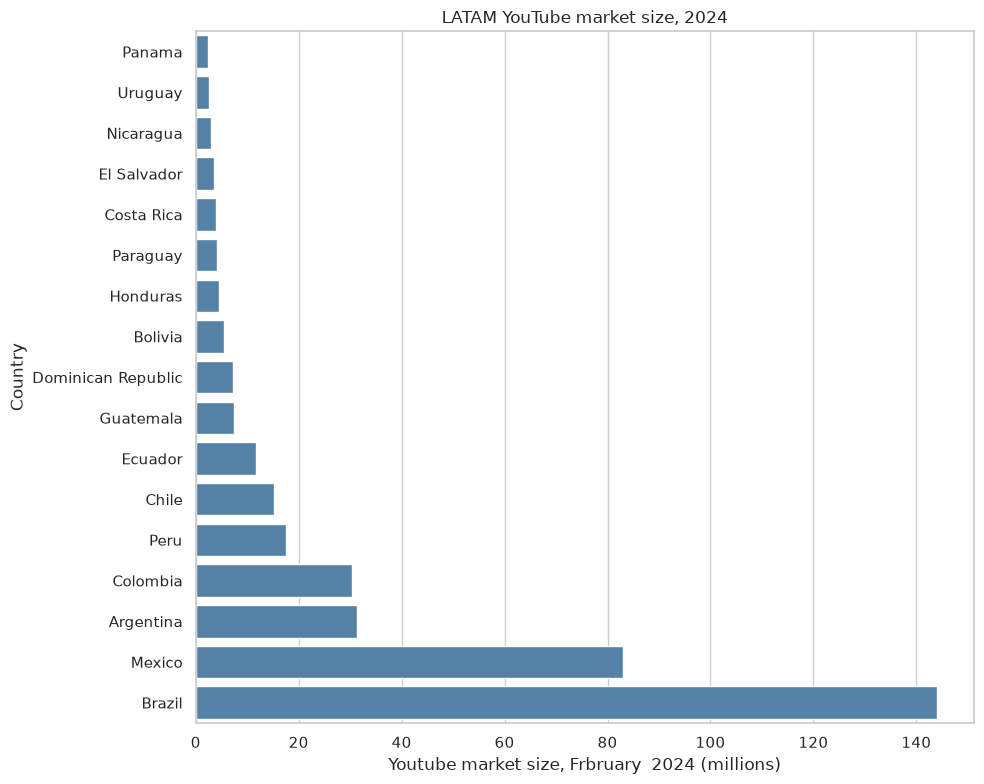

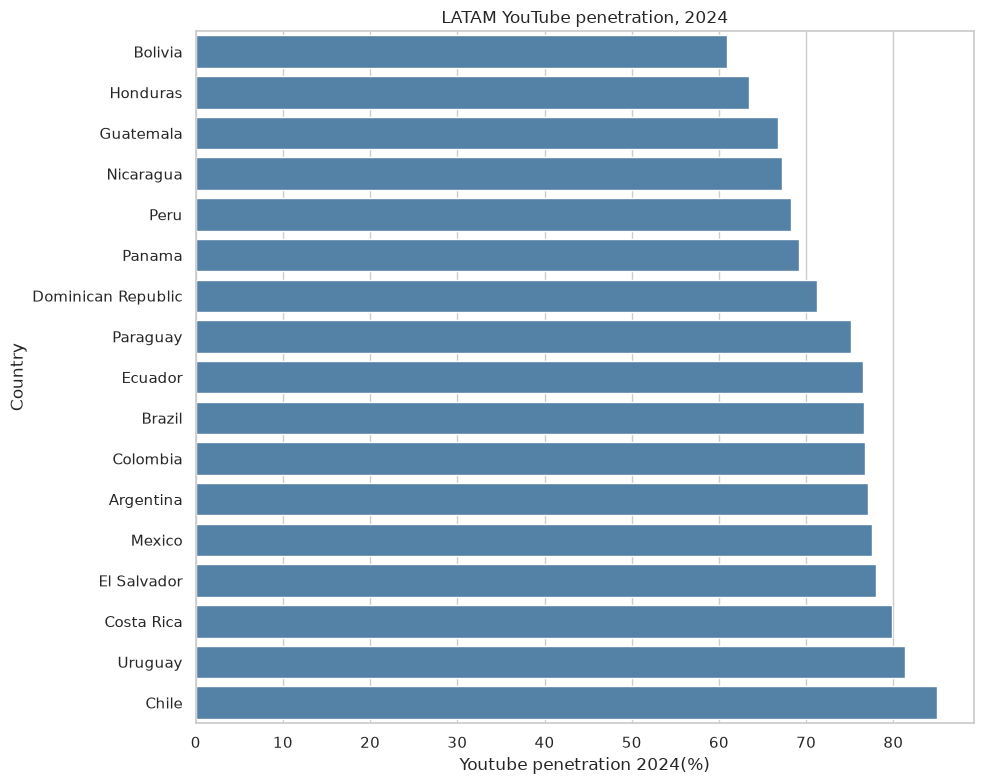

In [9]:
figures_dir = Path("/home/mikes/ChallengeDT/outputs/figures")
figures_dir.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

by_users = latam.sort_values("users_2024", ascending=True)


fig, ax = ptl.subplots(figsize=(10, 8))


#Chart A
sns.barplot(
    data=by_users,
    x=by_users["users_2024"] / 1_000_000,
    y="country",
    order=by_users["country"],
    color="steelblue",
    errorbar=None,
    ax=ax
    )

ax.set_xlabel("Youtube market size, Frbruary  2024 (millions)")
ax.set_ylabel("Country")
ax.set_title("LATAM YouTube market size, 2024")
fig.tight_layout()
fig.savefig(figures_dir / "01_latam_users_2024.png", dpi=150)
ptl.show()

#Chart B
fig, ax = ptl.subplots(figsize=(10, 8))

by_penetration = latam.sort_values("penetration_2024", ascending=True)
sns.barplot(
    data=by_penetration,
    x=by_penetration["penetration_2024"],
    y="country",
    order=by_penetration["country"],
    color="steelblue",
    errorbar=None,
    ax=ax
)

ax.set_xlabel("Youtube penetration 2024(%)")
ax.set_ylabel("Country")
ax.set_title("LATAM YouTube penetration, 2024")
fig.tight_layout()
fig.savefig(figures_dir / "02_latam_penetration_2024.png", dpi=150)
ptl.show()



# Conclusions

In Februaray 2024, Brazil has the most YouTube users in this LATAM sample, so it is the largets market by volume. Chile has the highest penetration (above 80%), so size and saturation do not rank countries the same way. Peru is a relatively large market with lower penetration than Brazil, Mexico, Argentina, and Colombia, which suggests more unused headroom in a still-sizeable populaton. Uruguay (and Panama) have few users but already high penetration, so they are small, crewded markets rather than expansion targets. Puerto Rico was excluded because it is a US territory. Penetration is a percentage proxy: this file does not list non-users directly.